# Task1

Ro'yxat ichida lug'atlar berilgan: 

`students = [{"name": "Ali", "score": 85}, {"name": "Vali", "score": 60}, {'name': 'Abror', 'score': 90}, {'name': 'Jasur', 'score': 56}, {'name': 'Malika', 'score': 100}]`

Ballari 70 dan yuqori bo'lgan talabalarning ismlarini ro'yxat ko'rinishida qaytaring.

#### Expected output: `['Ali', 'Abror', 'Malika']`


In [3]:
students = [
    {"name": "Ali", "score": 85}, 
    {"name": "Vali", "score": 60}, 
    {'name': 'Abror', 'score': 90}, 
    {'name': 'Jasur', 'score': 56}, 
    {'name': 'Malika', 'score': 100}
]

students_names = []

for student in students:
    if student["score"] > 70:
        students_names.append(student["name"])
        
students_names

['Ali', 'Abror', 'Malika']

# Task2

Berilgan matndagi barcha raqamlarni ajratib olib, ularning ko'paytmasini qaytaruvchi `digit_multiply(s)` funksiyasini yozing. Agar matnda raqam bo'lmasa, 0 qaytarsin.

Input: "Python programming language was created in 1991"

Output : 81

Input: "abcd12340"

Output: 0

In [15]:
def digit_multiply(text):
    result = 1
    num = False
    
    for t in text:
        if t.isdigit():
            result *= int(t)
            num = True
            
    return result if num else 0


digit_multiply("Python programming language was created in 1991")       


81

# Task 3

`Library` nomli database va Books jadvalini yarating (Title, Author, Year). 

Unga quyidagi 3 ta kitobni

[("Python Basics", "Author A", 2020),
("Data Structures and Algorithms", "Author B", 2005),
("Web Development with Python", "Author C", 2019)]

 qo'shing va 2010-yildan keyin chop etilgan kitoblarning faqat Title (nomi)ni chiqaring.


`Expected output: [('Python Basics',), ('Web Development with Python',)]`

In [ ]:
import sqlite3

conn = sqlite3.connect('Library.db')

cursor = conn.cursor()

cursor.execute("""
            create table if not exists Books(
                Title text,
                Author text,
                Year date
            )    
""")

insert_val = [("Python Basics", "Author A", 2020),
            ("Data Structures and Algorithms", "Author B", 2005),
            ("Web Development with Python", "Author C", 2019)]

cursor.executemany(
    "INSERT INTO books (title, author, year) VALUES (?, ?, ?)",
    insert_val
)

conn.commit()

cursor.execute("""
            select *from Books
            where Year > 2010
""")

result = cursor.fetchall()
print(result)

conn.close()

[('Python Basics', 'Author A', 2020), ('Web Development with Python', 'Author C', 2019)]


# Task 4

`products.json` faylida mahsulotlar ro'yxati bor. Foydalanuvchidan mahsulot nomi va narxini input orqali olib, faylga yangi mahsulot qo'shuvchi dastur yozing va hosil bo'lgan json fayldagi barcha elementlarni ekranga chiqaring.

In [8]:
import json

products = []

with open('products.json', 'r') as file:
    products = json.load(file)

    product_name = input("Mahsulot nomini kiriting: ")
    product_price = int(input("Mahsulot narxini kiriting: "))
    
    new_products = {'name': product_name, 'price': product_price}
    
    products.append(new_products)
    

with open('new_products.json', 'w') as f:
    json.dump(products, f, indent=4)
    
for product in products:
    print(product)
    

{'name': 'Monitor', 'price': 150}
{'name': 'Sichqoncha', 'price': 25}
{'name': 'Laptop', 'price': 700}
{'name': 'Air Pods', 'price': 100}
{'name': 'Laptop', 'price': 1500}
{'name': 'airpords', 'price': 200000}


# Task 5

students_data.csv faylida Name, Age, Grade ustunlari bor.

Yoshi 18 dan katta va Grade (baho) 4 dan yuqori bo'lgan o'quvchilarni filtrlang.

Har bir yosh guruhidagi o'quvchilar sonini hisoblang.

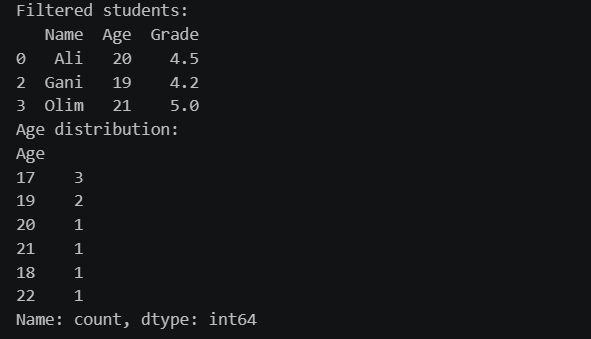

In [14]:
import pandas as pd

students_data = pd.read_csv('students_data.csv')

filtered_students = students_data[(students_data['Age'] > 18) & (students_data['Grade'] > 4)]
filtered_students

age_distribution = students_data.groupby('Age', as_index=False).agg(
    TotalCount=('Age', 'count')).sort_values(by='TotalCount', ascending=False)
age_distribution

,Age,TotalCount
0,17,3
2,19,2
1,18,1
3,20,1
4,21,1
5,22,1


# Task 6

sales.csv fayli berilgan (Date, Product, Amount).

Mahsulotlar bo'yicha umumiy sotuv miqdorini (Amount) hisoblang.

Natijani Bar chart (ustunli diagramma) ko'rinishida chizib ko'rsating.

x, y o'qlari va bar chartni o'ziga ham nom bering

`Expected output`

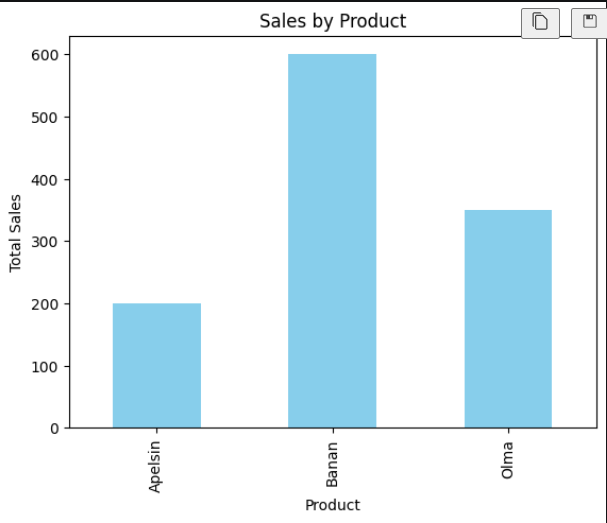

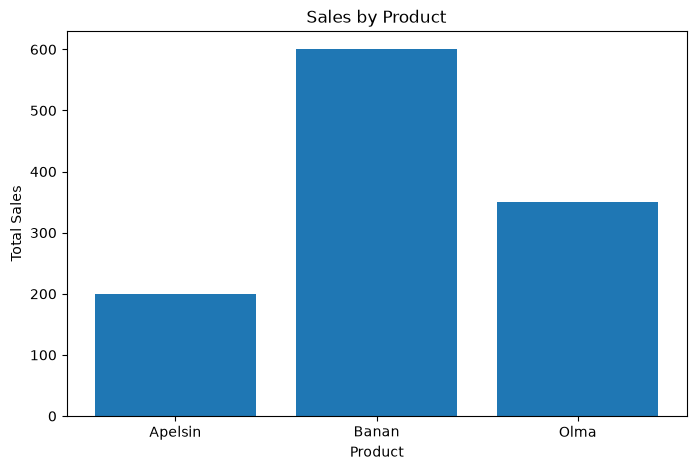

In [ ]:
import matplotlib.pyplot as plt

df = pd.read_csv("sales.csv")

result = df.groupby("Product", as_index=False)["Amount"].sum()

plt.figure(figsize=(8, 5))
plt.bar(result["Product"], result["Amount"])

plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")

plt.show()